In [210]:
import numpy as np
import pandas as pd

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [211]:
df=pd.read_csv('car_fuel_efficiency_2026.csv')
features=['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']
df = df[features]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

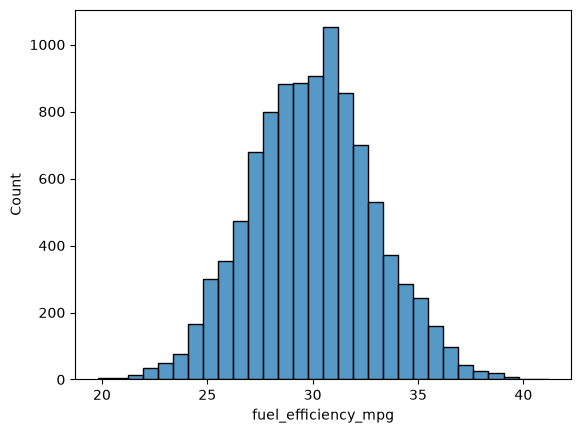

In [212]:
sns.histplot(df.fuel_efficiency_mpg,bins=30)
#It doesn't have long tails 

In [213]:
# Question 1
# There's one column with missing values. What is it?

df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [214]:
# Question 2
# What's the median (50% percentile) for variable 'horsepower'?

df.horsepower.median()

np.float64(254.0)

In [215]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]



In [216]:
# Question 3
# We need to deal with missing values for the column from Q1.
# We have two options: fill it with 0 or with the mean of this variable.
# Try both options. For each, train a linear regression model without regularization using the code from the lessons.
# For computing the mean, use the training only!
# Use the validation dataset to evaluate the models and compare the RMSE of each option.
# Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
# Which option gives better RMSE?

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [217]:
df_train_0 = df_train.copy()
df_train_0.horsepower = df_train_0.horsepower.fillna(0)

media = df_train.horsepower.mean()

df_train_mean = df_train.copy()
df_train_mean.horsepower = df_train_mean.horsepower.fillna(media)

target = "fuel_efficiency_mpg"

X_train_0 = df_train_0.drop(columns=[target])
y_train_0 = df_train_0[target]

X_train_mean = df_train_mean.drop(columns=[target])
y_train_mean = df_train_mean[target]


# Validation: fill 0
df_val_0 = df_val.copy()
df_val_0.horsepower = df_val_0.horsepower.fillna(0)

X_val_0 = df_val_0.drop(columns=[target])
y_val = df_val_0[target]


# Validation: fill mean
df_val_mean = df_val.copy()
df_val_mean.horsepower = df_val_mean.horsepower.fillna(media)

X_val_mean = df_val_mean.drop(columns=[target])


w_0, w = train_linear_regression(X_train_0, y_train_0)
y_pred = w_0 + X_val_0.dot(w)
aux = rmse(y_val, y_pred)

print('RMSE for fill 0: %f' % aux)


w_0, w = train_linear_regression(X_train_mean, y_train_mean)
y_pred = w_0 + X_val_mean.dot(w)
aux = rmse(y_val, y_pred)

print('RMSE for fill mean: %f' % aux)


RMSE for fill 0: 2.205293
RMSE for fill mean: 2.201817


In [218]:
# Now let's train a regularized linear regression.
# For this question, fill the NAs with 0.
# Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
# Use RMSE to evaluate the model on the validation dataset.
# Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
# Which r gives the best RMSE?

def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [219]:
best_r = 0
best_aux = float('inf')

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train_0, y_train_0, r=r)

    y_pred = w_0 + X_val_0.dot(w)
    aux = rmse(y_val, y_pred)

    print('With r=%f, rmse=%.4f' % (r, aux))

    if aux < best_aux:
        best_aux = aux
        best_r = r

print('Best r=%f, rmse=%.4f' % (best_r, best_aux))


With r=0.000000, rmse=2.2053
With r=0.010000, rmse=2.2058
With r=0.100000, rmse=2.2241
With r=1.000000, rmse=2.3492
With r=5.000000, rmse=2.4094
With r=10.000000, rmse=2.4195
With r=100.000000, rmse=2.4292
Best r=0.000000, rmse=2.2053


In [220]:
# Question 5
# We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
# Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
# For each seed, do the train/validation/test split with 60%/20%/20% distribution.
# Fill the missing values with 0 and train a model without regularization.
# For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
# What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
# Round the result to 3 decimal digits (round(std, 3))


scores = []


for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    df_train_0 = df_train.copy()
    df_train_0.horsepower = df_train_0.horsepower.fillna(0)
    target = "fuel_efficiency_mpg"

    X_train_0 = df_train_0.drop(columns=[target])
    y_train_0 = df_train_0[target]

    df_val_0 = df_val.copy()
    df_val_0.horsepower = df_val_0.horsepower.fillna(0)

    X_val_0 = df_val_0.drop(columns=[target])
    y_val = df_val_0[target]

    w_0, w = train_linear_regression(X_train_0, y_train_0)
    y_pred = w_0 + X_val_0.dot(w)
    aux = rmse(y_val, y_pred)
    scores.append(aux)

std = np.std(scores)
std = round(std,3)
print('Standard deviation', std)

Standard deviation 0.029


In [221]:
# Question 6
# Split the dataset like previously, use seed 9.
# Combine train and validation datasets.
# Fill the missing values with 0 and train a model with r=0.001.
# What's the RMSE on the test dataset?


n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_train=pd.concat([df_train,df_val])

df_train_0 = df_train.copy()
df_train_0.horsepower = df_train_0.horsepower.fillna(0)

target = "fuel_efficiency_mpg"

X_train_0 = df_train_0.drop(columns=[target])
y_train_0 = df_train_0[target]

df_test_0 = df_test.copy()
df_test_0.horsepower = df_test_0.horsepower.fillna(0)

X_test_0 = df_test_0.drop(columns=[target])
y_test = df_test_0[target]

w_0, w = train_linear_regression_reg(X_train_0, y_train_0, r=0.001)
y_pred = w_0 + X_test_0.dot(w)
aux = rmse(y_pred,y_test)
print(round(aux,3))



2.236
